# Question 1

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt
from tqdm import tqdm

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(28*28, 50)
        self.fc2 = nn.Linear(50,50)
        self.fc3 = nn.Linear(50,50)
        self.fc4 = nn.Linear(50,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
# model = nn.Sequential(Normalize(), Net())
std_model = nn.Sequential(
    Normalize(),
    nn.Flatten(),
    nn.Linear(28*28, 50), nn.ReLU(),
    nn.Linear(50, 50), nn.ReLU(),
    nn.Linear(50, 50), nn.ReLU(),
    nn.Linear(50, 10),
)

std_model = std_model.to(device)
std_model.train()


Sequential(
  (0): Normalize()
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=784, out_features=50, bias=True)
  (3): ReLU()
  (4): Linear(in_features=50, out_features=50, bias=True)
  (5): ReLU()
  (6): Linear(in_features=50, out_features=50, bias=True)
  (7): ReLU()
  (8): Linear(in_features=50, out_features=10, bias=True)
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    start = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')
    
    train_time = time.time() - start
    print(f'Standard training time: {train_time:.1f}s')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

# Part a

In [3]:
def pgd_linf_untargeted(model, x, labels, k, eps, eps_step):
    model.eval()
    ce_loss = torch.nn.CrossEntropyLoss()
    adv_x = x.clone().detach()
    adv_x.requires_grad_(True) 
    for _ in range(k):
        adv_x.requires_grad_(True)
        model.zero_grad()
        output = model(adv_x)
        loss = ce_loss(output, labels)
        loss.backward()

        step = eps_step * adv_x.grad.sign()
        adv_x = adv_x + step
        adv_x = torch.clamp(adv_x, x - eps, x + eps)
        adv_x = torch.clamp(adv_x, 0, 1)
        adv_x = adv_x.clone().detach()
   
    return adv_x

def test_model_on_single_attack(model, attack='pgd_linf', eps=0.1):
    model.eval()
    tot_test, tot_acc, tot_clean = 0.0, 0.0, 0.0
    for batch_idx, (x_batch, y_batch) in tqdm(enumerate(test_loader), total=len(test_loader), desc="Evaluating"):
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        if attack == 'pgd_linf':
            x_adv = pgd_linf_untargeted(model, x_batch, y_batch, 10, eps, eps/4)
            y_adv = model(x_adv).argmax(dim=1)
        else:
            pass
        
        # get the testing accuracy and update tot_test and tot_acc
        tot_acc += (y_batch == y_adv).sum().item()
        tot_test += x_batch.shape[0]
        tot_clean += (model(x_batch).argmax(dim=1) == y_batch).sum().item()

    print('Standard accuracy %.5lf' % (tot_clean/tot_test))
    print('Robust accuracy %.5lf' % (tot_acc/tot_test), f'on {attack} attack with eps = {eps}')

In [4]:
train_model(std_model, 10)
test_model(std_model)

Epoch 1/10, Loss: 1.328
Epoch 2/10, Loss: 0.379
Epoch 3/10, Loss: 0.289
Epoch 4/10, Loss: 0.237
Epoch 5/10, Loss: 0.200
Epoch 6/10, Loss: 0.175
Epoch 7/10, Loss: 0.156
Epoch 8/10, Loss: 0.142
Epoch 9/10, Loss: 0.131
Epoch 10/10, Loss: 0.120
Standard training time: 79.5s
Accuracy on images: 96.16


In [5]:
test_model_on_single_attack(std_model, attack='pgd_linf', eps=0.1)

Evaluating: 100%|██████████| 157/157 [00:04<00:00, 38.83it/s]

Standard accuracy 0.96160
Robust accuracy 0.07860 on pgd_linf attack with eps = 0.1


In [6]:
def interval_forward(model, l, u):

    for layer in list(model)[:-1]:
        if isinstance(layer, nn.Linear):
            mid, rad = (u + l) / 2, (u - l) / 2
            mid = layer(mid)
            rad = rad @ layer.weight.abs().t()
            l, u = mid - rad, mid + rad
        else: # Normalize Flatten ReLU
            l, u = layer(l), layer(u)

    return l, u

def worst_case_logits(model, l, u, y):

    W, b = model[-1].weight, model[-1].bias
    W_diff = W.unsqueeze(0) - W[y].unsqueeze(1)
    b_diff = b.unsqueeze(0) - b[y].unsqueeze(1)
    mid, rad = (u + l) / 2, (u - l) / 2
    z_mid = torch.bmm(W_diff, mid.unsqueeze(2)).squeeze(2) + b_diff
    z_rad = torch.bmm(W_diff.abs(), rad.unsqueeze(2)).squeeze(2)

    return z_mid + z_rad

def ibp_loss(model, images, labels, eps, kappa):
    criterion = nn.CrossEntropyLoss()
    fit_loss = criterion(model(images), labels)

    l = (images - eps).clamp(0, 1)
    u = (images + eps).clamp(0, 1)
    l, u = interval_forward(model, l, u)
    z_hat = worst_case_logits(model, l, u, labels)
    robust_loss = criterion(z_hat, labels)

    return kappa * fit_loss + (1 - kappa) * robust_loss

def train_IBP_model(model, num_epochs=10, warmup_epochs=1, ramp_epochs=5):
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    steps_per_epoch = len(train_loader)
    warmup_steps = warmup_epochs * steps_per_epoch
    ramp_steps = ramp_epochs * steps_per_epoch
    step = 0
    start = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            t = min(max(step - warmup_steps, 0) / ramp_steps, 1.0)
            eps = t * 0.1                               # 0 -> 0.1
            kappa = 1.0 - t * 0.5                       # 1 -> 0.5

            optimizer.zero_grad()
            loss = ibp_loss(model, images, labels, eps, kappa)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            step += 1

        print(f'Epoch {epoch+1}/{num_epochs}, eps={eps:.3f}, kappa={kappa:.2f}, Loss: {running_loss/steps_per_epoch:.3f}')

    train_time = time.time() - start
    print(f'IBP training time: {train_time:.1f}s')

In [7]:
ibp_model = nn.Sequential(
    Normalize(),
    nn.Flatten(),
    nn.Linear(28*28, 50), nn.ReLU(),
    nn.Linear(50, 50), nn.ReLU(),
    nn.Linear(50, 50), nn.ReLU(),
    nn.Linear(50, 10),
)

ibp_model = ibp_model.to(device)
ibp_model.train()

Sequential(
  (0): Normalize()
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=784, out_features=50, bias=True)
  (3): ReLU()
  (4): Linear(in_features=50, out_features=50, bias=True)
  (5): ReLU()
  (6): Linear(in_features=50, out_features=50, bias=True)
  (7): ReLU()
  (8): Linear(in_features=50, out_features=10, bias=True)
)

In [8]:
train_IBP_model(ibp_model, 10)
test_model(ibp_model)

Epoch 1/10, eps=0.000, kappa=1.00, Loss: 0.357
Epoch 2/10, eps=0.020, kappa=0.90, Loss: 0.273
Epoch 3/10, eps=0.040, kappa=0.80, Loss: 0.337
Epoch 4/10, eps=0.060, kappa=0.70, Loss: 0.400
Epoch 5/10, eps=0.080, kappa=0.60, Loss: 0.491
Epoch 6/10, eps=0.100, kappa=0.50, Loss: 0.618
Epoch 7/10, eps=0.100, kappa=0.50, Loss: 0.645
Epoch 8/10, eps=0.100, kappa=0.50, Loss: 0.595
Epoch 9/10, eps=0.100, kappa=0.50, Loss: 0.568
Epoch 10/10, eps=0.100, kappa=0.50, Loss: 0.550
IBP training time: 111.9s
Accuracy on images: 94.29


In [9]:
test_model_on_single_attack(ibp_model, attack='pgd_linf', eps=0.1)

Evaluating: 100%|██████████| 157/157 [00:04<00:00, 36.80it/s]

Standard accuracy 0.94290
Robust accuracy 0.83230 on pgd_linf attack with eps = 0.1


| Model   | Standard acc. | PGD robust acc. (ε = 0.1) | Train time (10 epochs) |
| -------- | ------------- | ------------------------- | ---------------------- |
| Standard | 96.16%        | 7.86%                     | 79.5s                  |
| IBP      | 94.29%        | 83.23%                    | 111.9s                 |

# Part b

In [15]:
def interval_analysis(model, x, y, eps):
    """Returns boolean tensor: True if image is verified robust"""
    lo = (x - eps).clamp(0, 1)
    hi = (x + eps).clamp(0, 1)
    lo, hi = interval_forward(model, lo, hi)
    z_hat = worst_case_logits(model, lo, hi, y)
    return (z_hat <= 0).all(dim=1)

def verified_accuracy(model, eps):
    model.eval()
    verified = 0
    total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            verified += interval_analysis(model, x, y, eps).sum().item()
            total += y.size(0)
    return 100 * verified / total

In [16]:
epsilons = np.linspace(0.01, 0.1, 10)
results = []
for eps in epsilons:
    acc = verified_accuracy(ibp_model, eps)
    results.append(acc)
    print(f"eps = {eps:.2f}: {acc:.2f}% of inputs can be proven robust, the rest cannot be proven anything")

eps = 0.01: 93.31% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.02: 92.32% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.03: 91.12% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.04: 89.71% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.05: 88.25% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.06: 86.88% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.07: 84.89% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.08: 82.76% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.09: 80.32% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.10: 77.45% of inputs can be proven robust, the rest cannot be proven anything


In [26]:
def find_adversarial_examples(model, eps, k=10, max_keep=5):
    
    eps_step = eps / 4
    model.eval()
    n_unverified, n_attacked = 0, 0
    examples = []

    for x, y in test_loader:
        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            verified = interval_analysis(model, x, y, eps)
            correct = model(x).argmax(dim=1) == y

        correct_unverified_mask = correct & ~verified
        x_u, y_u = x[correct_unverified_mask], y[correct_unverified_mask]
        n_unverified += (~verified).sum().item()
        if len(y_u) == 0:
            continue

        x_adv = pgd_linf_untargeted(model, x_u, y_u, k, eps, eps_step)
        with torch.no_grad():
            y_adv = model(x_adv).argmax(dim=1)
        failed = y_adv != y_u
        n_attacked += failed.sum().item()

        for i in torch.nonzero(failed).flatten():
            if len(examples) < max_keep:
                examples.append((x_u[i].cpu(), x_adv[i].cpu(), y_u[i].item(), y_adv[i].item()))

    total = len(test_loader.dataset)
    print(f'eps={eps:.2f}: unverified {n_unverified}/{total}, PGD adversarial examples found: {n_attacked}')

    return examples

def show_adversarial_examples(examples, eps):
    n = len(examples)
    if n == 0:
        print(f'No adversarial examples found at eps={eps:.2f}')
        return
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.4))
    axes = np.array(axes).reshape(2, n)
    for i, (x, x_adv, y, y_adv) in enumerate(examples):
        axes[0, i].imshow(x.squeeze(), cmap='gray')
        axes[0, i].set_title(f'orig: {y}')
        axes[1, i].imshow(x_adv.squeeze(), cmap='gray')
        axes[1, i].set_title(f'adv: {y_adv}')
        axes[0, i].axis('off')
        axes[1, i].axis('off')
    fig.suptitle(f'eps = {eps:.2f}')
    plt.show()


eps=0.01: unverified 669/10000, PGD adversarial examples found: 80


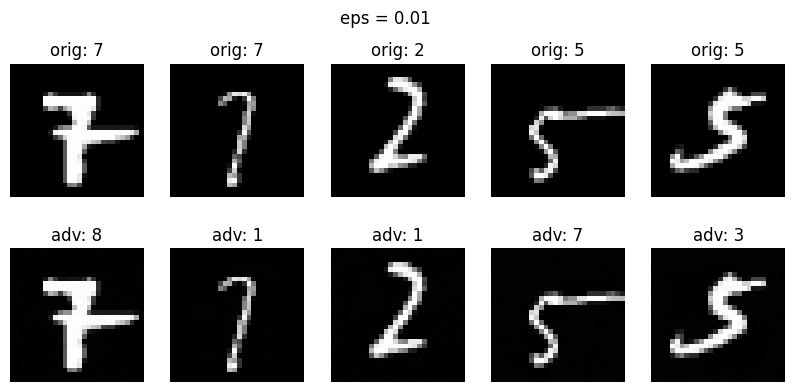

eps=0.02: unverified 768/10000, PGD adversarial examples found: 158


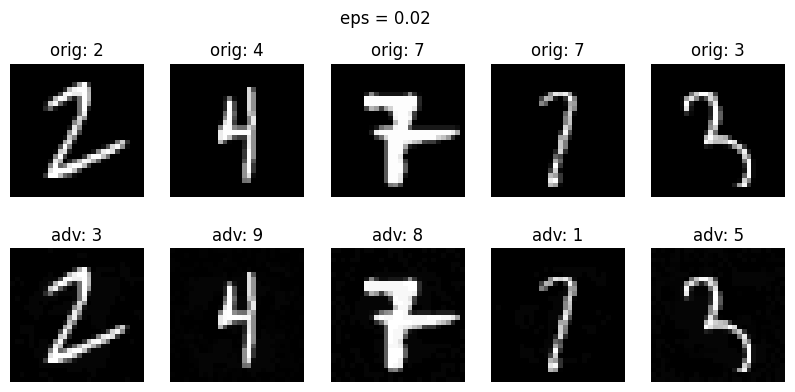

eps=0.03: unverified 888/10000, PGD adversarial examples found: 262


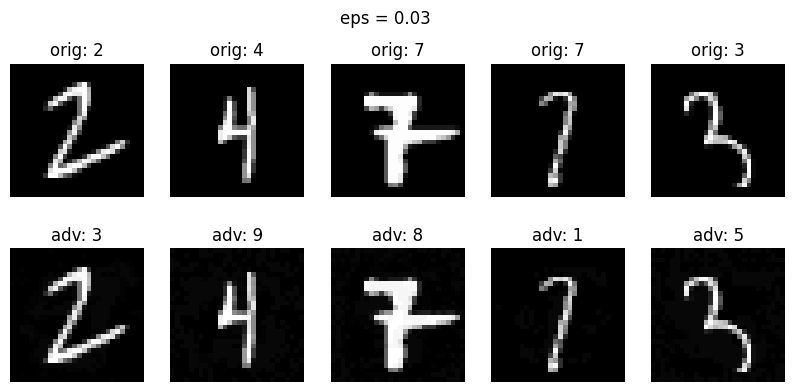

eps=0.04: unverified 1029/10000, PGD adversarial examples found: 349


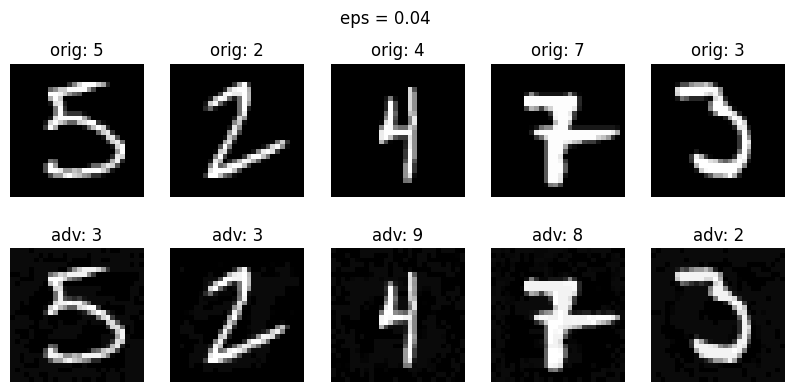

eps=0.05: unverified 1175/10000, PGD adversarial examples found: 461


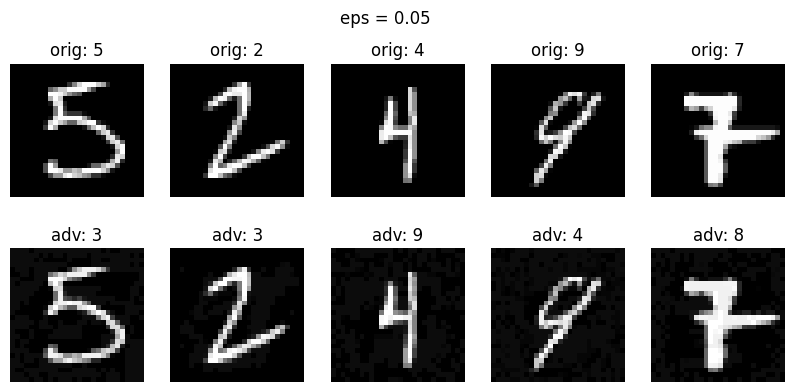

eps=0.06: unverified 1312/10000, PGD adversarial examples found: 550


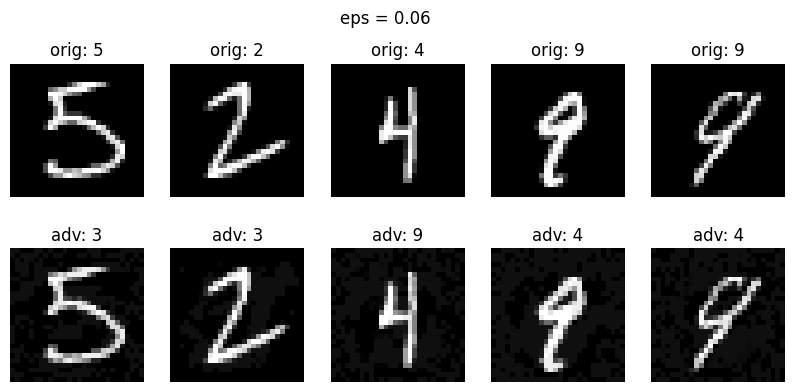

eps=0.07: unverified 1511/10000, PGD adversarial examples found: 685


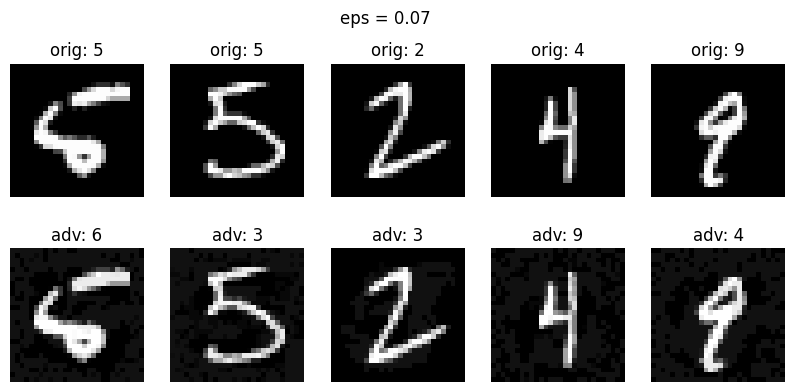

eps=0.08: unverified 1724/10000, PGD adversarial examples found: 802


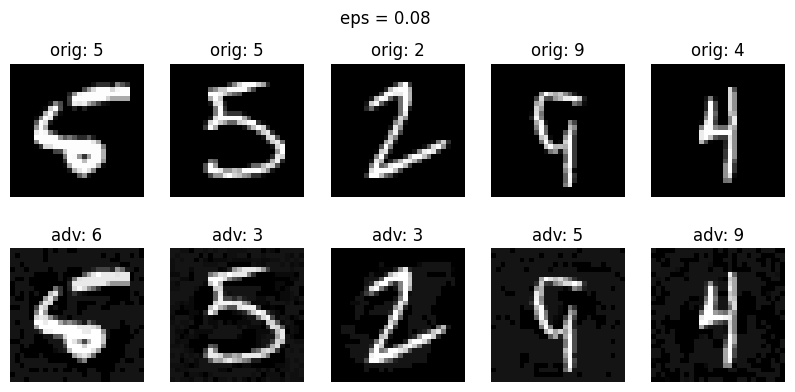

eps=0.09: unverified 1968/10000, PGD adversarial examples found: 945


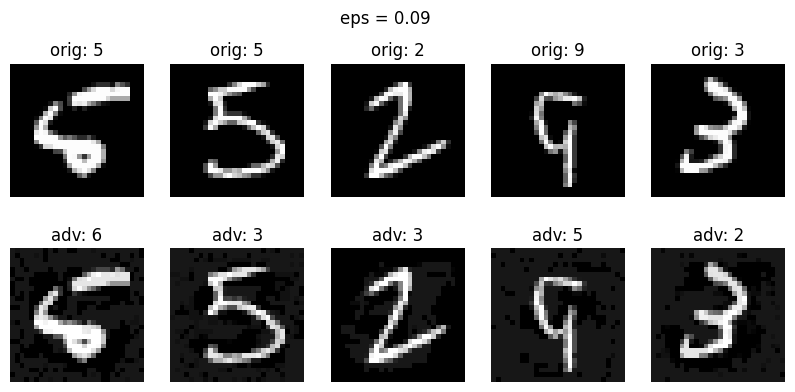

eps=0.10: unverified 2255/10000, PGD adversarial examples found: 1108


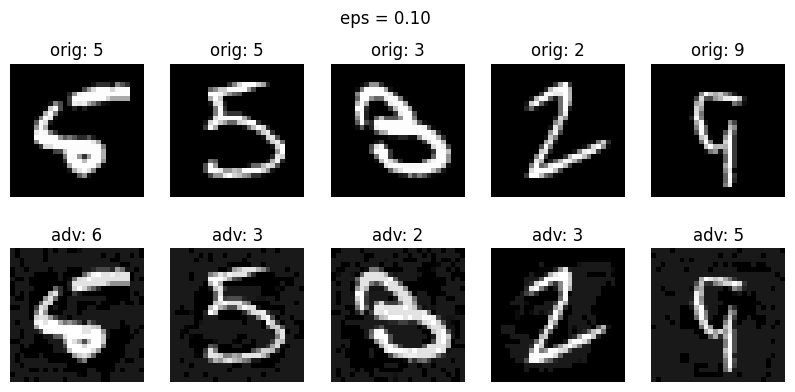

In [27]:
for eps in epsilons:
    ex = find_adversarial_examples(ibp_model, eps)
    show_adversarial_examples(ex, eps)

## Analysis
Once past the eps=0.06, the adversarial examples have a very clear blur in the background. The attack is trying to use the dark regions in the background to change the prediction into something else. Larger eps seem to have more examples that look cleaner and less ambiguous, for example, the 3rd image from eps=0.10, which disappeared when trying to attack with esp=0.09. Further up there is the 2nd image of eps=0.04 disappearing at eps=0.03. Mostly expected, with more unverified and adversarial examples found as eps increases. Most adversarial examples are images that does look like a number from another class, such as 4 and 9 from the last image in eps=0.08. There are examples which does not look like the missclassification, such as the last image in eps=0.10, which disappears in eps=0.09

Note: The order is consistent, the test loader isn’t shuffled, and the plots show only the first 5 adversarial examples found at each eps. Hence any smaller eps sits inside bigger eps, and that means examples present in larger eps but disappear in smaller eps mean that that image either verified or PGD failed.